# Analisis Pendapatan Transaksi POS 2024–2025

Tujuan:
1. Membaca file `paket_a_transaksi_pos_2024_2025.csv`
2. Menangani *missing value* dan data kotor lainnya
3. Menghitung total pendapatan per tahun (2024 dan 2025), dengan memperhatikan **diskon** dan **status** transaksi

## 1. Import library & baca file

In [1]:
import pandas as pd
import numpy as np

FILE = "paket_a_transaksi_pos_2024_2025.csv"

# dtype=str agar format asli (tanggal campur, harga '13.500' / '7500,00') tidak rusak saat dibaca
df_raw = pd.read_csv(FILE, dtype=str)
print("Jumlah baris:", len(df_raw))
df_raw.head()

Jumlah baris: 5030


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## 2. Eksplorasi awal

In [2]:
print("Missing value per kolom:")
print(df_raw.isna().sum())
print()
print("Baris duplikat persis :", df_raw.duplicated().sum())
print("ID transaksi duplikat :", df_raw["id_transaksi"].duplicated().sum())
print()
print("Distribusi status:")
print(df_raw["status"].value_counts())
print()
print("Distribusi diskon (%):")
print(df_raw["diskon_persen"].value_counts().sort_index())

Missing value per kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Baris duplikat persis : 30
ID transaksi duplikat : 30

Distribusi status:
status
SELESAI    4749
BATAL       191
RETUR        90
Name: count, dtype: int64

Distribusi diskon (%):
diskon_persen
0     3848
10     420
15     271
20     145
5      346
Name: count, dtype: int64


In [3]:
# Cek format tanggal & harga yang tidak seragam
pola_tgl = df_raw["tanggal"].str.replace(r"\d", "9", regex=True).value_counts()
pola_harga = df_raw["harga_satuan"].str.replace(r"\d", "9", regex=True).value_counts()
print("Pola tanggal:\n", pola_tgl, "\n")
print("Pola harga:\n", pola_harga)

Pola tanggal:
 tanggal
9999-99-99    4839
99-99-9999     105
99/99/9999      86
Name: count, dtype: int64 

Pola harga:
 harga_satuan
99999       3974
9999         960
99999,99      40
99.999        38
9999,99       11
9.999          7
Name: count, dtype: int64


**Temuan masalah data:**
- `kode_kasir` ada yang kosong (missing value).
- Ada baris duplikat persis (transaksi tercatat dua kali).
- Format `tanggal` campur: `YYYY-MM-DD`, `DD-MM-YYYY`, `DD/MM/YYYY`.
- Format `harga_satuan` campur: `13000`, `7500,00` (koma desimal), `13.500` (titik ribuan).
- `kode_produk` ada spasi/huruf kecil, dan ada kode tidak dikenal (`XXX...`).
- `jumlah` ada yang negatif dan ada yang tidak masuk akal (ratusan–ribuan, padahal jumlah normal 1–12).
- `status` ada `SELESAI`, `BATAL`, `RETUR` → hanya `SELESAI` yang dihitung sebagai pendapatan.

## 3. Pembersihan data

In [4]:
df = df_raw.copy()

# 3.1 Hapus duplikat persis
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplikat dihapus: {n_dup} -> sisa {len(df)} baris")

# 3.2 Rapikan teks
for kol in ["id_transaksi", "kode_gerai", "kode_kasir", "kode_produk", "status"]:
    df[kol] = df[kol].str.strip().str.upper()

# 3.3 Missing value: kode_kasir tidak memengaruhi nilai pendapatan,
#     jadi baris dipertahankan dan diisi 'TIDAK_DIKETAHUI'
print("Missing kode_kasir:", df["kode_kasir"].isna().sum())
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK_DIKETAHUI")

# 3.4 Seragamkan tanggal
def parse_tanggal(s):
    s = s.strip()
    if len(s) == 10 and s[4] == "-":                # 2024-12-28
        return pd.to_datetime(s, format="%Y-%m-%d")
    return pd.to_datetime(s.replace("/", "-"), format="%d-%m-%Y")   # 26/03/2025 atau 23-12-2024

df["tanggal"] = df["tanggal"].map(parse_tanggal)
df["tahun"] = df["tanggal"].dt.year

# 3.5 Seragamkan harga ('7500,00' -> 7500 ; '13.500' -> 13500)
def parse_harga(s):
    s = s.strip()
    if "," in s:                     # koma = desimal, titik = ribuan
        s = s.replace(".", "").replace(",", ".")
    else:                            # hanya titik -> titik ribuan
        s = s.replace(".", "")
    return float(s)

df["harga_satuan"] = df["harga_satuan"].map(parse_harga)

# 3.6 Tipe numerik
df["jumlah"] = df["jumlah"].astype(int)
df["diskon_persen"] = df["diskon_persen"].astype(int)

print("\nMissing value setelah pembersihan:")
print(df.isna().sum())
print("\nRentang tanggal:", df["tanggal"].min().date(), "s/d", df["tanggal"].max().date())
df.dtypes

Duplikat dihapus: 30 -> sisa 5000 baris
Missing kode_kasir: 260



Missing value setelah pembersihan:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
tahun            0
dtype: int64

Rentang tanggal: 2024-01-01 s/d 2025-12-31


id_transaksi                str
tanggal          datetime64[us]
kode_gerai                  str
kode_kasir                  str
kode_produk                 str
jumlah                    int64
harga_satuan            float64
diskon_persen             int64
status                      str
tahun                     int32
dtype: object

## 4. Validasi `jumlah`

Nilai `jumlah` yang valid pada dataset ini adalah 1, 2, 3, 4, 6, atau 12.
Nilai **negatif** dan nilai **> 12** (mis. 2375, 1456) dianggap salah input dan **dikeluarkan** dari perhitungan.

In [5]:
print("Distribusi jumlah:")
print(df["jumlah"].value_counts().sort_index().to_string())

df["jumlah_valid"] = (df["jumlah"] > 0) & (df["jumlah"] <= 12)
print("\nBaris jumlah tidak valid:", (~df["jumlah_valid"]).sum())
df.loc[~df["jumlah_valid"], ["id_transaksi", "tanggal", "jumlah", "harga_satuan", "diskon_persen", "status"]].sort_values("jumlah")

Distribusi jumlah:
jumlah
-12         2
-6          2
-4          4
-3          4
-2         12
-1         16
 1       1956
 2       1211
 3        743
 4        535
 6        353
 12       150
 641        1
 661        1
 746        1
 759        1
 892        1
 1280       1
 1301       1
 1310       1
 1456       1
 1983       1
 2093       1
 2375       1

Baris jumlah tidak valid: 52


,id_transaksi,tanggal,jumlah,harga_satuan,diskon_persen,status
41,TRX0240181,2025-02-16,-12,9000.0,0,SELESAI
1491,TRX0241078,2024-07-28,-12,13500.0,10,RETUR
2395,TRX0244256,2024-08-27,-6,7000.0,5,SELESAI
32,TRX0241782,2025-12-10,-6,45500.0,0,SELESAI
2483,TRX0240367,2025-10-02,-4,30000.0,0,SELESAI
2000,TRX0241916,2024-07-09,-4,6500.0,0,BATAL
4769,TRX0240044,2024-09-28,-4,46500.0,0,SELESAI
3488,TRX0242774,2025-09-26,-4,42000.0,0,SELESAI
2239,TRX0242099,2025-07-06,-3,32500.0,0,SELESAI
4736,TRX0241865,2025-02-19,-3,51000.0,0,SELESAI


## 5. Hitung pendapatan

Rumus per baris:

`pendapatan = jumlah × harga_satuan × (1 − diskon_persen / 100)`

Aturan:
- **Diskon** dipotong dari harga (pendapatan bersih setelah diskon).
- **Status**: hanya `SELESAI` yang dihitung. `BATAL` (dibatalkan) dan `RETUR` (barang dikembalikan) tidak dihitung.

In [6]:
df["pendapatan_kotor"] = df["jumlah"] * df["harga_satuan"]
df["pendapatan_bersih"] = df["pendapatan_kotor"] * (1 - df["diskon_persen"] / 100)

valid = df[(df["status"] == "SELESAI") & df["jumlah_valid"]]
print(f"Baris dipakai: {len(valid)} dari {len(df)}")

Baris dipakai: 4672 dari 5000


## 6. Hasil: pendapatan per tahun

In [7]:
hasil = (
    valid.groupby("tahun")
    .agg(jumlah_transaksi=("id_transaksi", "count"),
         pendapatan_kotor=("pendapatan_kotor", "sum"),
         total_diskon=("pendapatan_kotor", lambda x: x.sum() - valid.loc[x.index, "pendapatan_bersih"].sum()),
         pendapatan_bersih=("pendapatan_bersih", "sum"))
    .reset_index()
)

tampil = hasil.copy()
for k in ["pendapatan_kotor", "total_diskon", "pendapatan_bersih"]:
    tampil[k] = tampil[k].map(lambda v: f"Rp {v:,.0f}".replace(",", "."))
tampil

,tahun,jumlah_transaksi,pendapatan_kotor,total_diskon,pendapatan_bersih
0,2024,2327,Rp 130.883.500,Rp 3.477.025,Rp 127.406.475
1,2025,2345,Rp 138.664.000,Rp 3.662.900,Rp 135.001.100


In [8]:
for _, r in hasil.iterrows():
    print(f"Pendapatan bersih {int(r['tahun'])}: Rp {r['pendapatan_bersih']:,.0f}".replace(",", "."))

Pendapatan bersih 2024: Rp 127.406.475
Pendapatan bersih 2025: Rp 135.001.100


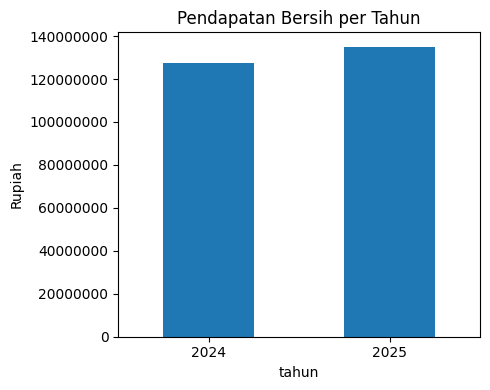

In [9]:
import matplotlib.pyplot as plt

ax = hasil.plot(x="tahun", y="pendapatan_bersih", kind="bar", legend=False, rot=0, figsize=(5, 4))
ax.set_title("Pendapatan Bersih per Tahun")
ax.set_ylabel("Rupiah")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.savefig("grafik_pendapatan_per_tahun.png", dpi=150)
plt.show()

## 7. Pengecekan: dampak status & data anomali

Tabel ini menunjukkan seberapa besar hasil berubah jika status/anomali **tidak** ditangani, sebagai bukti kenapa penanganan tadi penting.

In [10]:
skenario = pd.DataFrame({
    "Semua status, anomali ikut": df.groupby("tahun")["pendapatan_bersih"].sum(),
    "Hanya SELESAI, anomali ikut": df[df["status"] == "SELESAI"].groupby("tahun")["pendapatan_bersih"].sum(),
    "Hanya SELESAI, anomali dibuang (DIPAKAI)": valid.groupby("tahun")["pendapatan_bersih"].sum(),
})
skenario.map(lambda v: f"Rp {v:,.0f}".replace(",", "."))

,"Semua status, anomali ikut","Hanya SELESAI, anomali ikut","Hanya SELESAI, anomali dibuang (DIPAKAI)"
tahun,,,
2024,Rp 393.226.200,Rp 386.237.375,Rp 127.406.475
2025,Rp 271.871.425,Rp 257.085.100,Rp 135.001.100


## 8. Simpan hasil

In [11]:
hasil.to_csv("hasil_pendapatan_per_tahun.csv", index=False)
print("Tersimpan: hasil_pendapatan_per_tahun.csv, grafik_pendapatan_per_tahun.png")

Tersimpan: hasil_pendapatan_per_tahun.csv, grafik_pendapatan_per_tahun.png
